# Assignment No. 7 — Classification Algorithms and Imbalanced Datasets

**Dataset:** Customer churn (3,000 customers), generated inside the notebook with a fixed random seed, so no external file is needed. The target `Churn` is 1 if the customer left and 0 if the customer stayed.

| Feature | Description |
|---|---|
| Tenure | Months as a customer |
| MonthlyCharges | Monthly bill |
| SupportCalls | Number of customer-support calls |
| Age | Customer age |
| Contract | Month-to-month / One year / Two year |
| InternetService | DSL / Fiber optic / None |
| PaperlessBilling | Yes / No |

## Import libraries

In [1]:
# If imbalanced-learn is missing, run once:  !pip install imbalanced-learn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)
from imblearn.over_sampling import SMOTENC

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)

## Dataset: Customer churn

In [2]:
n = 3000
tenure          = np.random.randint(1, 73, n)
monthly_charges = np.round(np.random.uniform(20, 120, n), 2)
support_calls   = np.random.poisson(1.5, n)
age             = np.random.randint(18, 75, n)
contract        = np.random.choice(["Month-to-month", "One year", "Two year"], n, p=[0.5, 0.3, 0.2])
internet        = np.random.choice(["DSL", "Fiber optic", "None"], n, p=[0.35, 0.45, 0.20])
paperless       = np.random.choice(["Yes", "No"], n, p=[0.6, 0.4])

# Churn probability: higher for short tenure, month-to-month contracts, high bills, many support calls
score = (-3.0
         - 0.04 * tenure
         + 0.02 * monthly_charges
         + 0.35 * support_calls
         + np.where(contract == "Month-to-month", 1.2, np.where(contract == "One year", 0.0, -1.0))
         + np.where(internet == "Fiber optic", 0.5, 0.0))
prob = 1 / (1 + np.exp(-score))
churn = (np.random.uniform(0, 1, n) < prob).astype(int)

df = pd.DataFrame({
    "Tenure": tenure, "MonthlyCharges": monthly_charges, "SupportCalls": support_calls, "Age": age,
    "Contract": contract, "InternetService": internet, "PaperlessBilling": paperless, "Churn": churn,
})
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (3000, 8)
Missing values: 0


,Tenure,MonthlyCharges,SupportCalls,Age,Contract,InternetService,PaperlessBilling,Churn
0,52,114.30,1,32,One year,DSL,No,0
1,15,62.24,3,21,One year,None,No,0
2,72,57.73,2,74,One year,DSL,No,0
3,61,113.63,3,65,Month-to-month,Fiber optic,No,1
4,21,87.51,2,71,Two year,Fiber optic,Yes,0


## Question 1: Is the dataset balanced or imbalanced?

Class counts:
Churn
Stayed (0)     2401
Churned (1)     599
Name: count, dtype: int64

Class percentages:
Churn
Stayed (0)     80.03
Churned (1)    19.97
Name: proportion, dtype: float64

Imbalance ratio (majority : minority) = 4.0 : 1
Conclusion: IMBALANCED


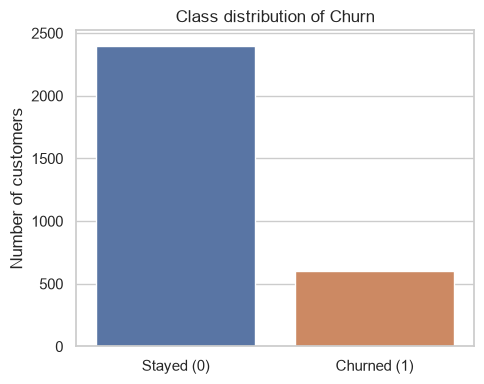

In [3]:
counts = df["Churn"].value_counts().sort_index()
percent = df["Churn"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(counts.rename({0: "Stayed (0)", 1: "Churned (1)"}))
print()
print("Class percentages:")
print(percent.round(2).rename({0: "Stayed (0)", 1: "Churned (1)"}))
print()
ratio = counts.max() / counts.min()
print(f"Imbalance ratio (majority : minority) = {ratio:.1f} : 1")
print("Conclusion:", "IMBALANCED" if percent.min() < 30 else "BALANCED")

plt.figure(figsize=(5, 4))
sns.barplot(x=["Stayed (0)", "Churned (1)"], y=counts.values, hue=["Stayed (0)", "Churned (1)"], legend=False)
plt.title("Class distribution of Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

**Result:** The dataset is **imbalanced**: only a minority of customers churned. A model trained on such data can reach high accuracy by always predicting "Stayed" while missing most churners. So accuracy alone is misleading, and recall, F1-score and ROC-AUC for the churn class are used as well.

## Question 2: Handle class imbalance with SMOTE

**SMOTE** (Synthetic Minority Over-sampling Technique) creates new, synthetic minority-class samples by interpolating between a minority sample and its nearest minority neighbours. Because the data has categorical columns, **SMOTENC** (the SMOTE variant for mixed numeric and categorical data) is used. The data is split first and SMOTE is applied **only to the training set**, so no synthetic samples leak into the test set.

In [4]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

cat_cols = ["Contract", "InternetService", "PaperlessBilling"]
num_cols = ["Tenure", "MonthlyCharges", "SupportCalls", "Age"]

smote = SMOTENC(categorical_features=cat_cols, random_state=42)
X_res, y_res = smote.fit_resample(X_train, y_train)

print("Training set BEFORE SMOTE:", y_train.value_counts().sort_index().to_dict())
print("Training set AFTER  SMOTE:", y_res.value_counts().sort_index().to_dict())
print("Test set (unchanged)     :", y_test.value_counts().sort_index().to_dict())

Training set BEFORE SMOTE: {0: 1801, 1: 449}
Training set AFTER  SMOTE: {0: 1801, 1: 1801}
Test set (unchanged)     : {0: 600, 1: 150}


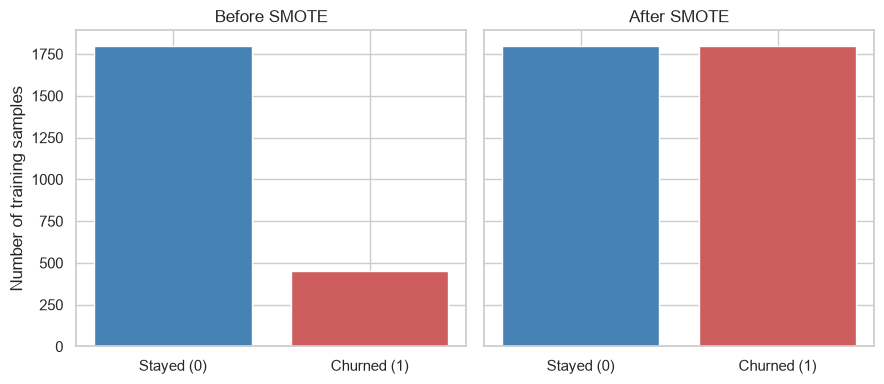

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, labels, title in zip(axes, [y_train, y_res], ["Before SMOTE", "After SMOTE"]):
    vc = labels.value_counts().sort_index()
    ax.bar(["Stayed (0)", "Churned (1)"], vc.values, color=["steelblue", "indianred"])
    ax.set_title(title)
axes[0].set_ylabel("Number of training samples")
plt.tight_layout()
plt.show()

## Questions 3, 4 and 5: Train SVM, Decision Tree and Random Forest (Bagging)

All models are trained on the SMOTE-balanced training data and evaluated on the original, untouched test set. Numeric features are scaled and categorical features are one-hot encoded.

- **SVM** finds the boundary (hyperplane) with the largest margin between the classes. It needs scaled features, so a `StandardScaler` is used; the RBF kernel handles non-linear boundaries.
- **Decision Tree** splits the data with if/else rules on the features. It is easy to interpret but can overfit, so `max_depth` is limited.
- **Random Forest** uses **bagging**: many decision trees are trained on random bootstrap samples of the training data (`bootstrap=True`) and their votes are combined. It also picks a random subset of features at each split. This reduces the overfitting of a single tree.

In [6]:
preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

models = {
    "SVM": Pipeline([("prep", preprocess),
                     ("clf", SVC(kernel="rbf", C=1.0, probability=True, random_state=42))]),
    "Decision Tree": Pipeline([("prep", preprocess),
                               ("clf", DecisionTreeClassifier(max_depth=5, random_state=42))]),
    "Random Forest (Bagging)": Pipeline([("prep", preprocess),
                               ("clf", RandomForestClassifier(n_estimators=200, bootstrap=True,
                                                              random_state=42))]),
}

fitted = {}
for name, model in models.items():
    model.fit(X_res, y_res)
    fitted[name] = model
    print(f"{name:<25} trained on {len(X_res)} samples")

SVM                       trained on 3602 samples
Decision Tree             trained on 3602 samples
Random Forest (Bagging)   trained on 3602 samples


## Question 6: Compare the performance of the three models

In [7]:
rows, preds, probas = [], {}, {}
for name, model in fitted.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    preds[name], probas[name] = y_pred, y_prob
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
SVM,0.7107,0.3707,0.6400,0.4694,0.7597
Decision Tree,0.7067,0.3674,0.6467,0.4686,0.7476
Random Forest (Bagging),0.7413,0.3866,0.5000,0.4360,0.7507


In [8]:
for name in fitted:
    print("=" * 55)
    print(name)
    print(classification_report(y_test, preds[name], target_names=["Stayed", "Churned"]))

SVM
              precision    recall  f1-score   support

      Stayed       0.89      0.73      0.80       600
     Churned       0.37      0.64      0.47       150

    accuracy                           0.71       750
   macro avg       0.63      0.68      0.64       750
weighted avg       0.79      0.71      0.73       750

Decision Tree
              precision    recall  f1-score   support

      Stayed       0.89      0.72      0.80       600
     Churned       0.37      0.65      0.47       150

    accuracy                           0.71       750
   macro avg       0.63      0.68      0.63       750
weighted avg       0.79      0.71      0.73       750

Random Forest (Bagging)
              precision    recall  f1-score   support

      Stayed       0.87      0.80      0.83       600
     Churned       0.39      0.50      0.44       150

    accuracy                           0.74       750
   macro avg       0.63      0.65      0.63       750
weighted avg       0.77      0.7

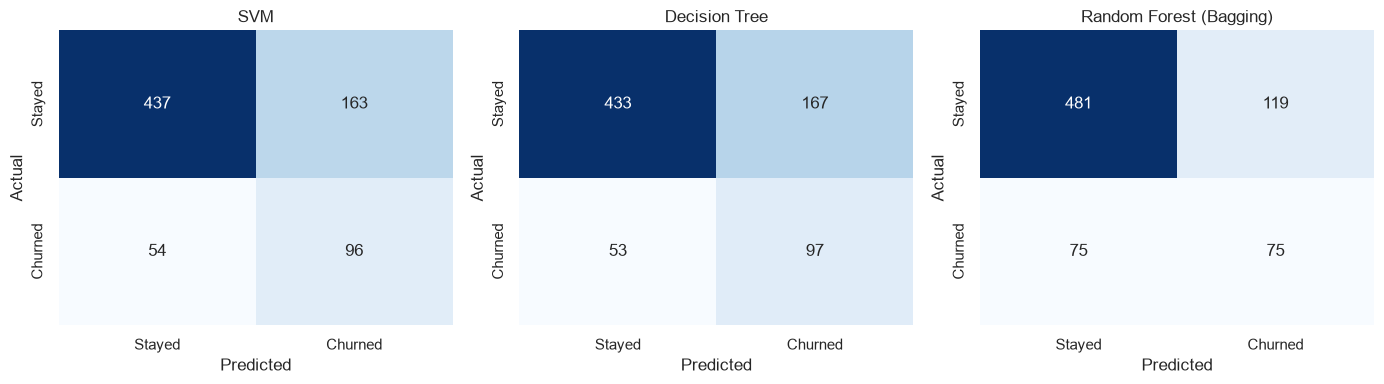

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes, fitted):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

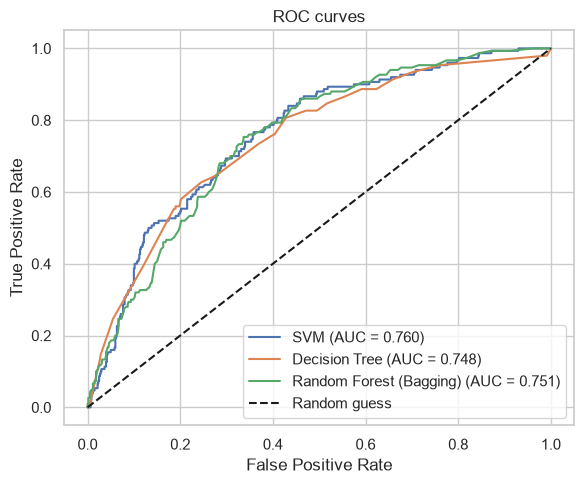

In [10]:
plt.figure(figsize=(6, 5))
for name in fitted:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probas[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.title("ROC curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

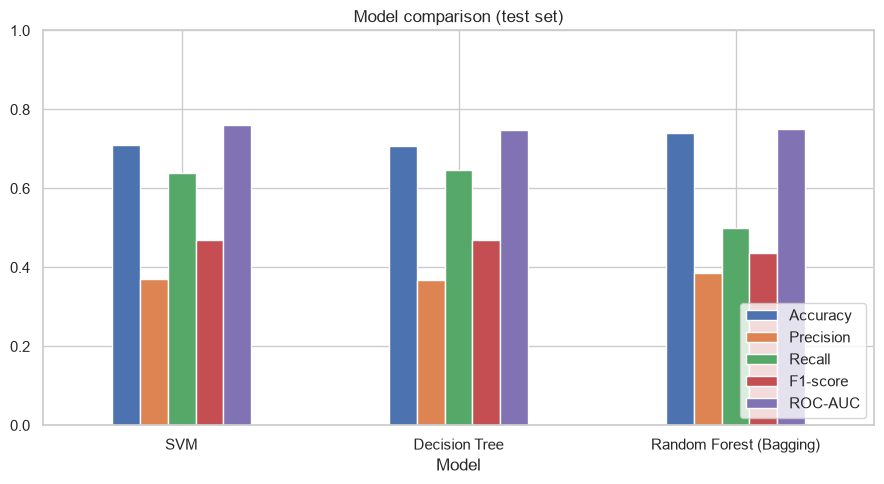

Best model by F1-score (churn class): SVM  ->  F1 = 0.4694


In [11]:
results[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
    kind="bar", figsize=(9, 5), rot=0)
plt.title("Model comparison (test set)")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best = results["F1-score"].idxmax()
print(f"Best model by F1-score (churn class): {best}  ->  F1 = {results.loc[best, 'F1-score']:.4f}")

### Extra check: does SMOTE actually help?

The same three models are trained on the original imbalanced training data (no SMOTE) and compared with the SMOTE versions on the churn class.

In [12]:
import copy
rows = []
for name, model in models.items():
    base = copy.deepcopy(model).fit(X_train, y_train)          # without SMOTE
    p_base, p_smote = base.predict(X_test), preds[name]
    rows.append({"Model": name,
                 "Recall (no SMOTE)": recall_score(y_test, p_base),
                 "Recall (SMOTE)": recall_score(y_test, p_smote),
                 "F1 (no SMOTE)": f1_score(y_test, p_base),
                 "F1 (SMOTE)": f1_score(y_test, p_smote)})
pd.DataFrame(rows).set_index("Model").round(4)

,Recall (no SMOTE),Recall (SMOTE),F1 (no SMOTE),F1 (SMOTE)
Model,,,,
SVM,0.2267,0.6400,0.3434,0.4694
Decision Tree,0.2267,0.6467,0.3091,0.4686
Random Forest (Bagging),0.2267,0.5000,0.3091,0.4360


## Short explanation of the results

**1. Class balance:** The dataset is imbalanced: about 80% of customers stayed and 20% churned (ratio 4 : 1).

**2. SMOTE:** SMOTENC increased the churn class in the training set from 449 to 1,801 samples, matching the majority class. The test set was left unchanged, so the results reflect real, imbalanced data.

**3. Model comparison (test set):**

| Model | Accuracy | Precision | Recall | F1-score | ROC-AUC |
|---|---|---|---|---|---|
| SVM | 0.711 | 0.371 | 0.640 | 0.469 | 0.760 |
| Decision Tree | 0.707 | 0.367 | 0.647 | 0.469 | 0.748 |
| Random Forest (Bagging) | 0.741 | 0.387 | 0.500 | 0.436 | 0.751 |

- **SVM** has the best F1-score and ROC-AUC, so it is the best overall balance between finding churners and avoiding false alarms.
- **Decision Tree** is almost as good as the SVM on recall and F1, and its rules are easy to read and explain.
- **Random Forest (Bagging)** has the highest accuracy and precision, but it catches the fewest churners (lowest recall), so its F1-score is the lowest. It is the better choice if false alarms are costly.
- **Effect of SMOTE:** Without SMOTE, every model found only about 23% of the churners (recall 0.227). With SMOTE, recall rose to 50–65% and the F1-score improved for all three models. The price is lower precision (more customers wrongly flagged as churners) and, for some models, a small change in accuracy. This is the usual trade-off, and for churn it is normally worth it, because losing a customer costs more than a retention offer sent by mistake.

**Note:** The scores are moderate (ROC-AUC about 0.75) because customer churn in this dataset is partly random. The differences between the three models are small and come from a single train/test split, so they should not be treated as a firm ranking. Cross-validation would give a more reliable comparison.